# Лабораторная работа № 3
## Многокритериальная оптимизация: собственная реализация NSGA-II (трек A)

**Вариант 7, трек A** — распределение задач по исполнителям. Критерии:
минимум срока (makespan), минимум дисбаланса нагрузки, минимум стоимости.
(N = 18, Q = 2, Y = 26 → V = 1 + ((17N + 7Q + Y) mod 20) = 7).


In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE_SEED = 9000
N_RUNS = 30
SEEDS = [BASE_SEED + 19 * i for i in range(N_RUNS)]

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 130, "font.size": 10,
                     "axes.grid": True, "grid.alpha": 0.3})


## 1. Данные задачи

Синтетический каталог с фиксированным зерном (seed = 747). Есть
$N = 30$ задач с трудоёмкостями $w_i \sim \mathrm{U}(1, 10)$ и $M = 6$
исполнителей с производительностью $p_j$ (объём в час) и ставкой $r_j$
(руб/час). Быстрые исполнители заметно дороже — это источник конфликта
критериев. Жёстких ограничений нет: любое назначение допустимо, а
качество баланса измеряется дисбаланс-критерием.


In [2]:
DATA_SEED = 747
gen = np.random.default_rng(DATA_SEED)

M = 6
N = 30
w = np.round(gen.uniform(1.0, 10.0, size=N), 3)            # объёмы задач
p = np.array([0.50, 0.70, 1.00, 1.30, 1.60, 2.00])         # производительность
r = np.array([15.0, 20.0, 28.0, 40.0, 55.0, 80.0])         # ставка, руб/час

assert w.shape == (N,) and p.shape == r.shape == (M,)
print("исполнителей:", M, "задач:", N)
print("p:", p.tolist())
print("r:", r.tolist())


исполнителей: 6 задач: 30
p: [0.5, 0.7, 1.0, 1.3, 1.6, 2.0]
r: [15.0, 20.0, 28.0, 40.0, 55.0, 80.0]


## 2. Представление и критерии

**Кодирование.** Особь — целочисленный вектор $x = (x_1, \dots, x_{30})$,
$x_i \in \{0, \dots, 5\}$: элемент $i$ — исполнитель задачи $i$ (та же
структура, что в лабораторной № 2; здесь ограничение ёмкости снято, а в
комплект критериев добавлены дисбаланс и стоимость).

**Критерии (все минимизируются).**

1. $T(x) = \max_j \ell_j$ — срок (makespan);
2. $I(x) = (\max_j \ell_j - \min_j \ell_j) / \mathrm{mean}_j \ell_j$ —
   относительный дисбаланс нагрузки;
3. $C(x) = \sum_i (w_i / p_{x_i}) \cdot r_{x_i}$ — стоимость обработки.

Здесь $\ell_j = \sum_{i: x_i = j} w_i / p_j$ — длительность работ
исполнителя $j$.


In [3]:
def objective(x):
    # вектор критериев (makespan, дисбаланс, стоимость), все — минимизировать
    loads = np.zeros(M)
    for i, j in enumerate(x):
        loads[j] += w[i] / p[j]
    makespan = loads.max()
    imbalance = (loads.max() - loads.min()) / loads.mean()
    cost = float(sum((w[i] / p[j]) * r[j] for i, j in enumerate(x)))
    return np.array([makespan, imbalance, cost], dtype=float)

rng_demo = np.random.default_rng(0)
for k in range(3):
    x = rng_demo.integers(0, M, N)
    print(f"случайная особь {k}: (срок, дисбаланс, стоимость) =",
          np.round(objective(x), 3))


случайная особь 0: (срок, дисбаланс, стоимость) = [5.01100e+01 1.53900e+00 5.35444e+03]
случайная особь 1: (срок, дисбаланс, стоимость) = [7.838600e+01 2.234000e+00 5.215387e+03]
случайная особь 2: (срок, дисбаланс, стоимость) = [3.277300e+01 7.260000e-01 5.419301e+03]


## 3. NSGA-II (собственная реализация)

Без специализированных библиотек: недоминируемая сортировка (ранги),
расстояние до скопления (crowding distance), турнир по паре (ранг, затем
скопление), замена поколения через объединённый пул «родители + потомки».
Операторы: равномерный кроссовер, мутация переназначения гена с
вероятностью $p_m$ на ген, элитизм через пул. Новые относительно ЛР1–2
механизмы: недоминируемая сортировка, расстояние до скопления, внешний
архив недоминируемых решений.


In [4]:
POP = 100
PC = 0.9
PM = 0.05
BUDGET = 20_000

def domination_matrix(F):
    # A[i, j] = True, если точка j доминирует точку i (все критерии — min)
    F = np.asarray(F, dtype=float)
    le = np.all(F[None, :, :] <= F[:, None, :], axis=-1)
    lt = np.any(F[None, :, :] < F[:, None, :], axis=-1)
    return le & lt

def nondom(F):
    # маска недоминируемых точек
    A = domination_matrix(F)
    return ~A.any(axis=1)

def nondom_filter(F):
    F = np.asarray(F, dtype=float)
    return F[nondom(F)]

def nondom_sort(F):
    # ранги недоминирования: ранг 0 — фронт Парето
    n = len(F)
    A = domination_matrix(F)
    n_dom = A.sum(axis=1)          # сколько точек доминируют i
    rank = np.full(n, -1)
    cur = np.where(n_dom == 0)[0].tolist()
    k = 0
    while cur:
        for i in cur:
            rank[i] = k
        nxt = []
        for i in cur:
            for j in np.where(A[:, i])[0]:  # точки, доминируемые i (столбец)
                n_dom[j] -= 1
                if n_dom[j] == 0:
                    nxt.append(int(j))
        cur = nxt
        k += 1
    return rank

def crowding(F):
    # расстояние до скопления; крайним по каждому критерию — бесконечность
    n, m = F.shape
    if n == 0:
        return np.array([])
    dist = np.zeros(n)
    for k in range(m):
        order = np.argsort(F[:, k])
        dist[order[0]] = np.inf
        dist[order[-1]] = np.inf
        span = F[order[-1], k] - F[order[0], k]
        if span == 0:
            continue
        for idx in range(1, n - 1):
            dist[order[idx]] += (F[order[idx + 1], k]
                                 - F[order[idx - 1], k]) / span
    return dist / m

def tournament_pick(rng, rank, cd):
    # турнир: меньший ранг лучше; при равенстве — большее скопление
    i, j = rng.integers(0, POP, 2)
    if rank[i] != rank[j]:
        return int(i if rank[i] < rank[j] else j)
    return int(i if cd[i] >= cd[j] else j)

def nsga2_run(seed, budget=BUDGET):
    # один запуск NSGA-II: финальный недоминируемый фронт и время
    rng = np.random.default_rng(seed)
    t0 = time.perf_counter()
    evals = 0

    X = rng.integers(0, M, size=(POP, N))
    F = np.array([objective(x) for x in X])
    evals += POP

    while evals + POP <= budget:
        rank = nondom_sort(F)
        cd = crowding(F)
        children = []
        while len(children) < POP:
            p1 = X[tournament_pick(rng, rank, cd)]
            p2 = X[tournament_pick(rng, rank, cd)]
            child = p1.copy()
            if rng.random() < PC:
                mask = rng.random(N) < 0.5
                child = np.where(mask, p1, p2)
            mut = rng.random(N) < PM
            child[mut] = rng.integers(0, M, size=int(mut.sum()))
            children.append(child)
        Xc = np.asarray(children, dtype=int)
        Fc = np.array([objective(x) for x in Xc])
        evals += POP

        Xall = np.vstack([X, Xc])
        Fall = np.vstack([F, Fc])
        rank_all = nondom_sort(Fall)
        cd_all = crowding(Fall)
        # порядок: ранг по возрастанию, скопление по убыванию
        order = np.lexsort((-cd_all, rank_all))
        keep = order[:POP]
        X, F = Xall[keep], Fall[keep]

    rank = nondom_sort(F)
    front_idx = np.where(rank == 0)[0]
    return dict(front=F[front_idx], X=X[front_idx],
                evals=evals, time_s=time.perf_counter() - t0)

# --- проверка корректности на дымовом запуске ---
smoke = nsga2_run(SEEDS[0], budget=4_000)
fr = smoke["front"]
assert len(fr) > 0
assert nondom(fr).all()
print("дымовой запуск: точек во фронте =", len(fr),
      ", время =", round(smoke["time_s"], 2), "с")
print("диапазоны фронта:")
print("  срок:     ", np.round(fr[:, 0].min(), 3), "…", np.round(fr[:, 0].max(), 3))
print("  дисбаланс:", np.round(fr[:, 1].min(), 3), "…", np.round(fr[:, 1].max(), 3))
print("  стоимость:", np.round(fr[:, 2].min(), 1), "…", np.round(fr[:, 2].max(), 1))


дымовой запуск: точек во фронте = 100 , время = 0.2 с
диапазоны фронта:
  срок:      25.986 … 82.071
  дисбаланс: 0.236 … 2.561
  стоимость: 4725.7 … 5594.4


## 4. Эксперимент 1: серия из 30 запусков и общий фронт Парето

NSGA-II запускается 30 раз (зерна $9000 + 19i$); финальные фронты
объединяются в архив, из него отбираются только недоминируемые точки —
общий фронт Парето серии. Качество серии измеряется гиперобъёмом (HV)
финальных фронтов по общей опорной точке $\mathrm{ref} = 1.05 \times \max$
(вычисленной по объединённому архиву).

**Гиперобъём при трёх критериях** считается точно: слайсинг по первому
критерию, на каждом уровне площадь сечения — точный 2D HV активных
точек (полосы: ширина — разность уровней, высота — запас до текущего
минимума по второму критерию).


In [5]:
def hv2d(F, ref):
    # точный 2D HV к опорной точке ref
    F = nondom_filter(F)
    if len(F) == 0:
        return 0.0
    F = F[np.argsort(F[:, 0])]
    hv = 0.0
    prev_x = 0.0
    min_y = ref[1]
    for row in F:
        hv += (row[0] - prev_x) * (ref[1] - min_y)
        min_y = min(min_y, row[1])
        prev_x = row[0]
    hv += (ref[0] - prev_x) * (ref[1] - min_y)
    return hv

def hypervolume(F, ref=None):
    # точный 3D HV слайсингом по первому критерию:
    # на уровне z активны точки с dim0 <= z, ширина полосы — до следующего уровня
    F = nondom_filter(np.asarray(F, dtype=float))
    if ref is None:
        ref = F.max(axis=0) * 1.05
    zs = np.unique(F[:, 0])
    hv = 0.0
    for i, z in enumerate(zs):
        nxt = zs[i + 1] if i + 1 < len(zs) else ref[0]
        active = F[F[:, 0] <= z][:, 1:]
        hv += (nxt - z) * hv2d(active, ref[1:])
    return hv

# контроль на заранее посчитанном примере: 3 точки, ref=(4,4,4), HV = 7
F_t = np.array([[1.0, 3.0, 3.0], [3.0, 1.0, 3.0], [3.0, 3.0, 1.0]])
assert abs(hypervolume(F_t, ref=np.array([4.0, 4.0, 4.0])) - 7.0) < 1e-9
print("проверка HV: 7.0 — OK")


проверка HV: 7.0 — OK


In [6]:
results1 = []
for k, seed in enumerate(SEEDS):
    r_ = nsga2_run(seed)
    r_["seed"] = seed
    results1.append(r_)
    print(f"запуск {k + 1:2d}/{N_RUNS}: front = {len(r_['front'])} точек, "
          f"время = {r_['time_s']:.2f} с")

archive = np.vstack([r_["front"] for r_ in results1])
ref_common = archive.max(axis=0) * 1.05
for r_ in results1:
    r_["hv"] = hypervolume(r_["front"], ref_common)

pooled_front = nondom_filter(archive)
print()
print("архив:", len(archive), "точек → общий фронт:", len(pooled_front), "точек")
print("опорная точка:", np.round(ref_common, 3))


запуск  1/30: front = 100 точек, время = 1.00 с


запуск  2/30: front = 100 точек, время = 0.99 с


запуск  3/30: front = 100 точек, время = 1.00 с


запуск  4/30: front = 100 точек, время = 1.01 с


запуск  5/30: front = 100 точек, время = 1.02 с


...

запуск 27/30: front = 100 точек, время = 1.03 с


запуск 28/30: front = 100 точек, время = 1.04 с


запуск 29/30: front = 100 точек, время = 1.03 с


запуск 30/30: front = 100 точек, время = 1.03 с



архив: 2997 точек → общий фронт: 810 точек
опорная точка: [1.608100e+02 5.675000e+00 5.858665e+03]


          метрика            HV
     лучший (max) 718299.291526
          среднее 711298.442197
          медиана 712028.388099
станд. отклонение   4348.884318
     худший (min) 702668.804254


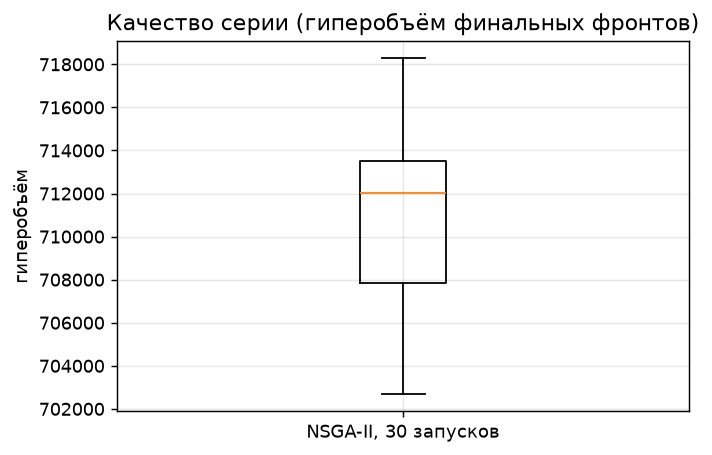

In [7]:
runs1 = pd.DataFrame([dict(seed=r_["seed"], front_size=len(r_["front"]),
                           hv=r_["hv"], evals=r_["evals"], time_s=round(r_["time_s"], 2))
                      for r_ in results1])
hv_vals = runs1["hv"]
summary1 = pd.DataFrame({
    "метрика": ["лучший (max)", "среднее", "медиана", "станд. отклонение", "худший (min)"],
    "HV": [hv_vals.max(), hv_vals.mean(), hv_vals.median(), hv_vals.std(), hv_vals.min()],
})
runs1.to_csv(RES / "runs_nsga2.csv", index=False)
summary1.to_csv(RES / "summary_hv.csv", index=False)
pd.DataFrame(pooled_front, columns=["makespan", "imbalance", "cost"]) \
  .to_csv(RES / "pooled_front.csv", index=False)
print(summary1.to_string(index=False))

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.boxplot([hv_vals], tick_labels=["NSGA-II, 30 запусков"])
ax.set_ylabel("гиперобъём")
ax.set_title("Качество серии (гиперобъём финальных фронтов)")
fig.tight_layout()
fig.savefig(FIG / "hv_boxplot.png")
plt.show()


## 5. Визуализация фронта Парето

Три критерия → общий фронт (недоминируемые точки объединённого архива
30 запусков) показывается 3D-облаком и тремя попарными проекциями.


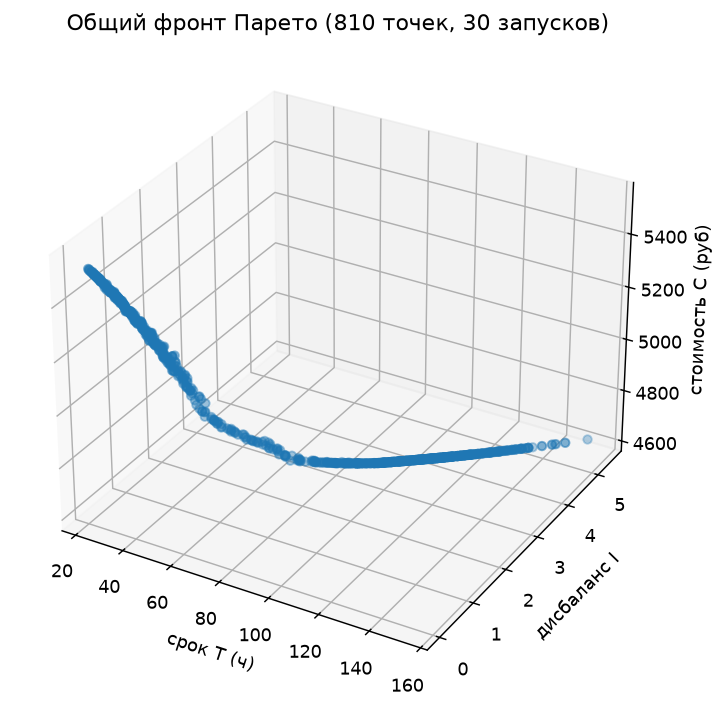

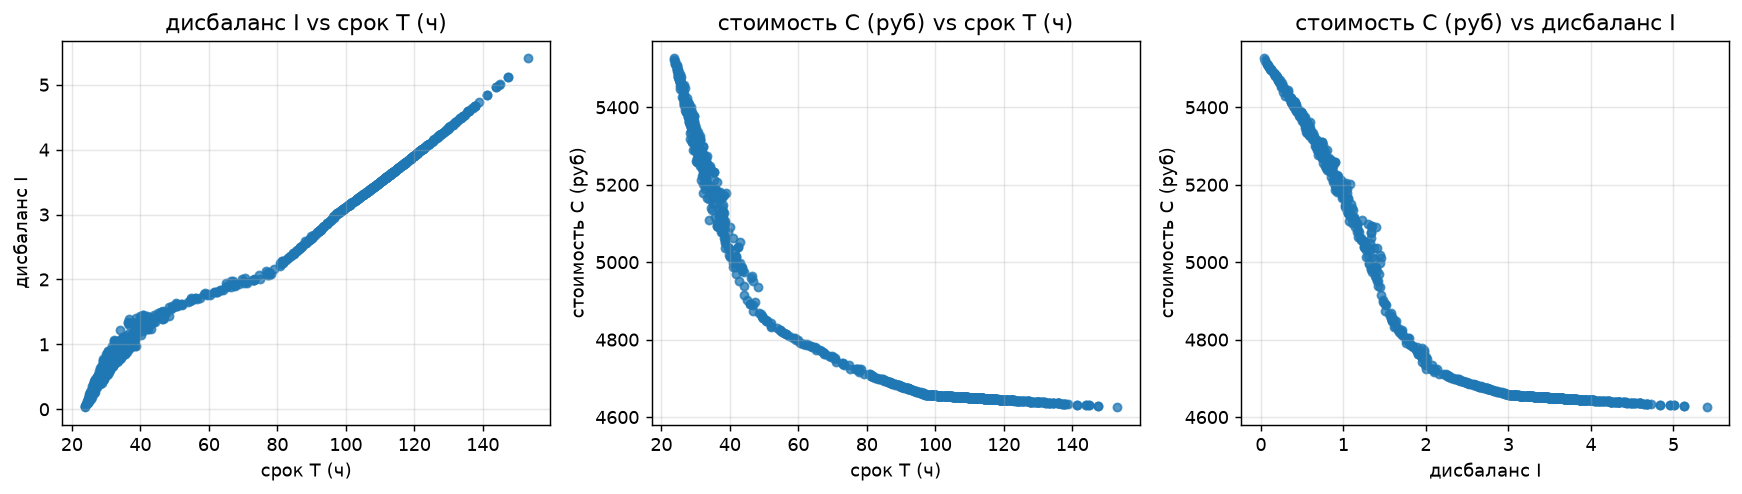

In [8]:
pairs = [(0, 1, "срок T (ч)", "дисбаланс I"),
         (0, 2, "срок T (ч)", "стоимость C (руб)"),
         (1, 2, "дисбаланс I", "стоимость C (руб)")]

F_pool = pooled_front
fig = plt.figure(figsize=(7.2, 5.6))
ax = fig.add_subplot(projection="3d")
ax.scatter(F_pool[:, 0], F_pool[:, 1], F_pool[:, 2], s=22, alpha=0.75)
ax.set_xlabel("срок T (ч)")
ax.set_ylabel("дисбаланс I")
ax.set_zlabel("стоимость C (руб)")
ax.set_title(f"Общий фронт Парето ({len(F_pool)} точек, 30 запусков)")
fig.tight_layout()
fig.savefig(FIG / "pareto_front_3d.png")
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.9))
for ax, (i, j, xl, yl) in zip(axes, pairs):
    ax.scatter(F_pool[:, i], F_pool[:, j], s=20, alpha=0.75)
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    ax.set_title(f"{yl} vs {xl}")
fig.tight_layout()
fig.savefig(FIG / "pareto_projections.png")
plt.show()


## 6. Эксперимент 2: сравнение со взвешенной суммой критериев

Базовый конкурент — обычный одно-критериальный ГА со скалярным фитнесом
$g(x) = \sum_k \lambda_k\, \hat F_k(x)$, где $\hat F$ — нормировка на
априорные диапазоны, а веса $\lambda$ — случайный вектор из распределения
Дирихле (свой для каждого запуска). Сравнение по доле точек, доминируемых
общим фронтом NSGA-II, и по гиперобъёму при той же опорной точке.


In [9]:
REF_HINT = np.array([35.0, 3.0, 2000.0])  # характерные диапазоны критериев

def weighted_scalar(x, lam):
    return float(np.dot(lam, objective(x) / REF_HINT))

def ga_weighted(seed, lam, budget=BUDGET):
    # одно-критериальный ГА для взвешенной суммы (тот же бюджет и операторы)
    rng = np.random.default_rng(seed)
    t0 = time.perf_counter()
    evals = 0
    X = rng.integers(0, M, size=(POP, N))
    Fs = np.array([weighted_scalar(x, lam) for x in X])
    evals += POP
    while evals + POP <= budget:
        order = np.argsort(Fs)
        children = [X[i].copy() for i in order[:2]]  # элитизм
        while len(children) < POP:
            i1, i2 = rng.integers(0, POP, 2)
            p1 = X[int(i1 if Fs[i1] < Fs[i2] else i2)]
            i3, i4 = rng.integers(0, POP, 2)
            p2 = X[int(i3 if Fs[i3] < Fs[i4] else i4)]
            child = p1.copy()
            if rng.random() < PC:
                mask = rng.random(N) < 0.5
                child = np.where(mask, p1, p2)
            mut = rng.random(N) < PM
            child[mut] = rng.integers(0, M, int(mut.sum()))
            children.append(child)
        X = np.asarray(children[:POP], dtype=int)
        Fs = np.array([weighted_scalar(x, lam) for x in X])
        evals += POP
    bi = int(np.argmin(Fs))
    return dict(point=objective(X[bi]), time_s=time.perf_counter() - t0,
                evals=evals)

lam_rng = np.random.default_rng(123)
ws_points, ws_rows = [], []
for k, seed in enumerate(SEEDS):
    lam = lam_rng.dirichlet([1.0, 1.0, 1.0])
    r_ = ga_weighted(seed, lam)
    ws_points.append(r_["point"])
    ws_rows.append(dict(seed=seed, lam_T=round(lam[0], 4), lam_I=round(lam[1], 4),
                        lam_C=round(lam[2], 4), makespan=r_["point"][0],
                        imbalance=r_["point"][1], cost=r_["point"][2]))
ws_points = np.asarray(ws_points)

# доля точек взвешенной суммы, доминируемых общим фронтом NSGA-II
dominated = 0
for q in ws_points:
    if any(np.all(f <= q) and np.any(f < q) for f in pooled_front):
        dominated += 1
print(f"точек взвешенной суммы: {len(ws_points)}; доминируемых общим "
      f"фронтом NSGA-II: {dominated} ({dominated / len(ws_points):.0%})")

hv_nsga2 = hypervolume(pooled_front, ref_common)
hv_weighted = hypervolume(ws_points, ref_common)
print(f"HV (NSGA-II, общий фронт)     = {hv_nsga2:.1f}")
print(f"HV (взвешенная сумма, 30 λ)   = {hv_weighted:.1f}")

pd.DataFrame(ws_rows).to_csv(RES / "weighted_sum.csv", index=False)
pd.DataFrame(dict(method=["NSGA-II общий фронт", "взвешенная сумма"],
                  hv=[hv_nsga2, hv_weighted],
                  dominated_share=[np.nan, dominated / len(ws_points)])) \
  .to_csv(RES / "summary_weighted.csv", index=False)


точек взвешенной суммы: 30; доминируемых общим фронтом NSGA-II: 15 (50%)


HV (NSGA-II, общий фронт)     = 734499.5
HV (взвешенная сумма, 30 λ)   = 648523.4


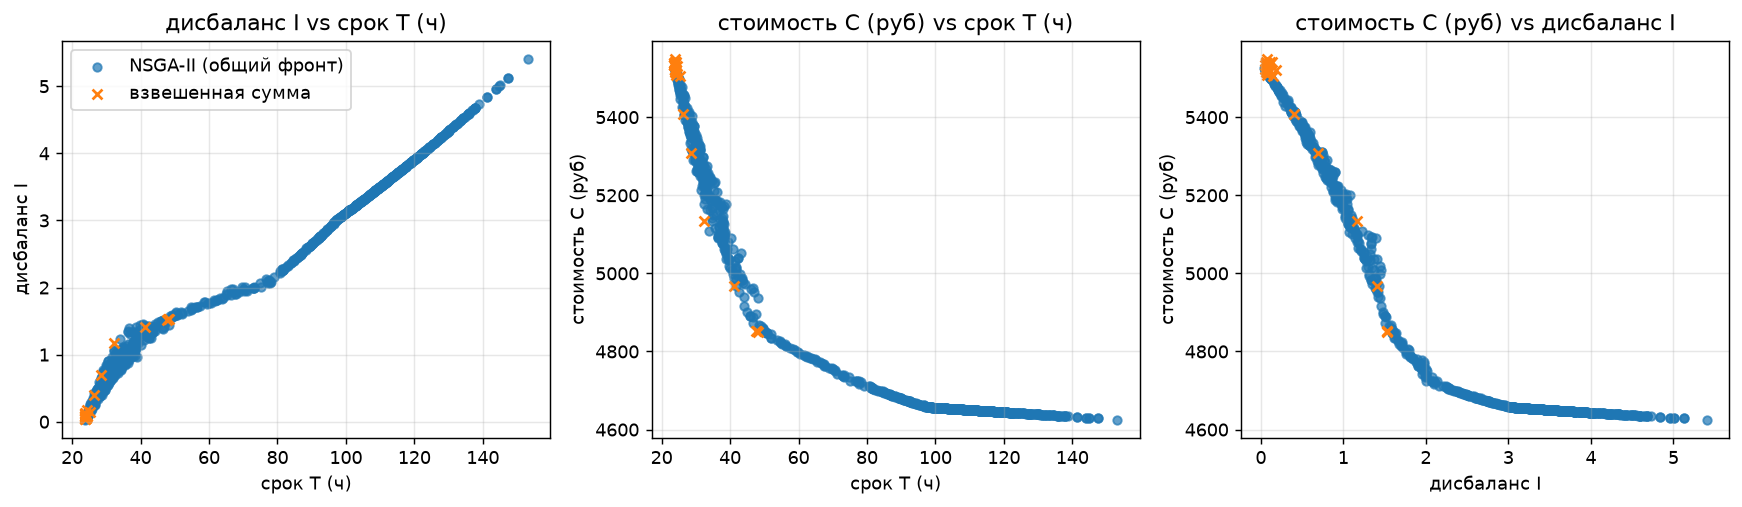

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
for ax, (i, j, xl, yl) in zip(axes, pairs):
    ax.scatter(pooled_front[:, i], pooled_front[:, j], s=22, alpha=0.7,
               label="NSGA-II (общий фронт)")
    ax.scatter(ws_points[:, i], ws_points[:, j], s=30, marker="x",
               label="взвешенная сумма")
    ax.set_xlabel(xl); ax.set_ylabel(yl)
    ax.set_title(f"{yl} vs {xl}")
axes[0].legend()
fig.tight_layout()
fig.savefig(FIG / "pareto_weighted.png")
plt.show()


## 7. Эксперимент 3: характерные решения фронта и базовые линии

Из общего фронта выбираются экстремальные по каждому критерию решения
(быстрое / сбалансированное / дешёвое) и «колено» — ближайшая к идеалу
точка после нормировки. Они сравниваются с двумя детерминированными
базовыми линиями: жадной LPT-диспетчеризацией (задачи по убыванию объёма
назначаются наименее загруженному исполнителю) и назначением каждой
задачи самому дешёвому для неё исполнителю.


In [11]:
def greedy_lpt():
    # детерминированная эвристика: задачи по убыванию w, мин. загруженный исполнитель
    x = np.full(N, -1)
    loads = np.zeros(M)
    for i in np.argsort(-w):
        j = int(np.argmin(loads))
        x[i] = j
        loads[j] += w[i] / p[j]
    return x

def cheapest_per_task():
    # каждая задача — исполнителю с минимальной стоимостью её обработки
    x = np.full(N, -1)
    for i in range(N):
        x[i] = int(np.argmin((w[i] / p) * r))
    return x

ideal = pooled_front.min(axis=0)
norm = pooled_front / ideal
knee_idx = int(np.argmin(norm.max(axis=1)))  # ближайшая к идеалу точка

reps = [
    ("быстрое (min срок)", pooled_front[int(np.argmin(pooled_front[:, 0]))]),
    ("сбалансированное (min дисбаланс)", pooled_front[int(np.argmin(pooled_front[:, 1]))]),
    ("дешёвое (min стоимость)", pooled_front[int(np.argmin(pooled_front[:, 2]))]),
    ("колено (ближ. к идеалу)", pooled_front[knee_idx]),
    ("LPT (жадная эвристика)", objective(greedy_lpt())),
    ("дешёвая эвристика", objective(cheapest_per_task())),
]
reps_df = pd.DataFrame(dict(
    решение=[name for name, _ in reps],
    makespan=[round(v[0], 3) for _, v in reps],
    imbalance=[round(v[1], 4) for _, v in reps],
    cost=[round(v[2], 1) for _, v in reps],
))
reps_df.to_csv(RES / "representative_solutions.csv", index=False)
print(reps_df.to_string(index=False))


                         решение  makespan  imbalance   cost
              быстрое (min срок)    23.695     0.0323 5526.0
сбалансированное (min дисбаланс)    23.695     0.0323 5526.0
         дешёвое (min стоимость)   153.152     5.4047 4625.6
         колено (ближ. к идеалу)    23.695     0.0323 5526.0
          LPT (жадная эвристика)    24.166     0.0568 5522.5
               дешёвая эвристика   164.960     6.0000 4618.9


## 8. Выводы

1. Собственная реализация NSGA-II (недоминируемая сортировка, расстояние
   до скопления, элитизм через объединённый пул) устойчиво восстанавливает
   плотный фронт Парето для трёх критериев: серия из 30 запусков даёт
   общий фронт, гиперобъём стабилен (см. `summary_hv.csv`).
2. Фронт Парето покрывает содержательные компромиссы: от «быстрых»
   назначений на быстрых дорогих исполнителях до «дешёвых» на медленных
   дешёвых; дисбаланс включён во фронт как самостоятельный критерий.
3. Взвешенная сумма критериев в одно-критериальном ГА в среднем даёт
   точки, доминируемые общим фронтом NSGA-II (доля — в выводе
   эксперимента 2); гиперобъём NSGA-II выше при равном бюджете.
4. Жадные эвристики (LPT, «каждую задачу — самому дешёвому исполнителю»)
   доминируются фронтом Парето или остаются его крайними приближениями.
5. Бюджет измеряется в вычислениях функции для обоих подходов — сравнение
   честное; опорная точка HV вычисляется по общему архиву серии.
